In [2]:
%pip install seaborn matplotlib pandas numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Replace with your exact CSV filename if different
df = pd.read_csv('retail_sales_dataset.csv')

# View first 5 rows
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom


In [4]:
print("Shape of dataset:", df.shape)
print("\n--- Data Info ---")
df.info()

print("\n--- Missing Values Count ---")
print(df.isnull().sum())

print("\n--- Summary Statistics (Numerical) ---")
df.describe()

Shape of dataset: (541909, 8)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  541909 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   541909 non-null  int64  
 7   Country      541909 non-null  object 
dtypes: float64(1), int64(2), object(5)
memory usage: 33.1+ MB

--- Missing Values Count ---
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

--- Summary Statistics (Numerical) ---


,Quantity,UnitPrice,CustomerID
count,541909.000000,541909.000000,541909.000000
mean,9.552250,4.611114,15272.795237
std,218.081158,96.759853,1737.934523
min,-80995.000000,-11062.060000,12346.000000
25%,1.000000,1.250000,13798.000000
50%,3.000000,2.080000,15145.000000
75%,10.000000,4.130000,16803.000000
max,80995.000000,38970.000000,18287.000000


In [7]:
date_col = 'InvoiceDate'

df[date_col] = pd.to_datetime(df[date_col])
df['Year_Month'] = df[date_col].dt.to_period('M')
df['Month_Name'] = df[date_col].dt.month_name()

In [6]:
print(df.columns.tolist())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


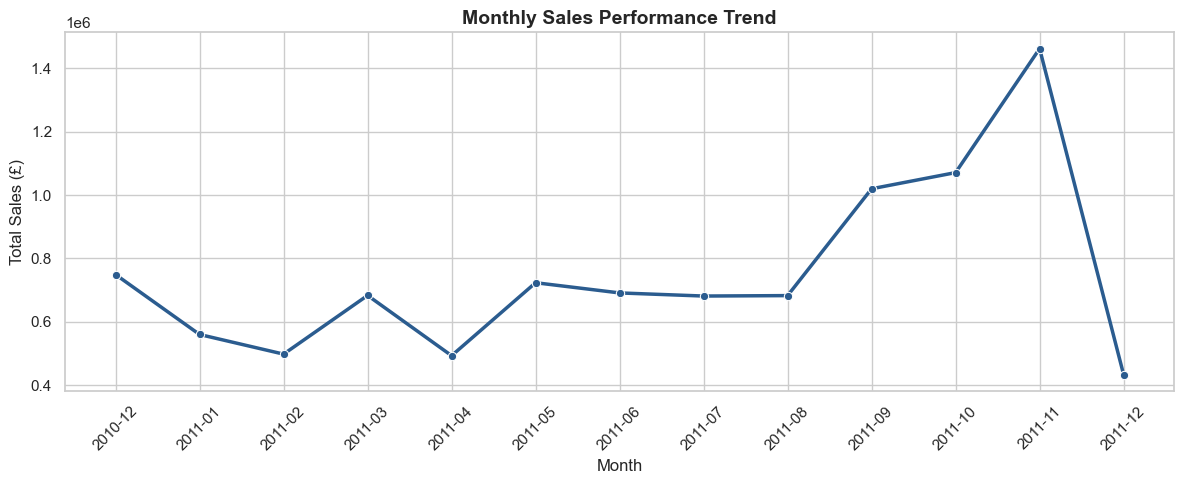

In [9]:
# Ensure TotalAmount exists
if 'TotalAmount' not in df.columns:
    df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Ensure Year_Month exists
if 'Year_Month' not in df.columns:
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
    df['Year_Month'] = df['InvoiceDate'].dt.to_period('M')

# Group total sales by month
sales_trend = df.groupby('Year_Month')['TotalAmount'].sum().reset_index()
sales_trend['Year_Month'] = sales_trend['Year_Month'].astype(str)

plt.figure(figsize=(12, 5))
sns.lineplot(data=sales_trend, x='Year_Month', y='TotalAmount', marker='o', color='#2b5c8f', linewidth=2.5)
plt.title('Monthly Sales Performance Trend', fontsize=14, weight='bold')
plt.xlabel('Month', fontsize=12)
plt.ylabel('Total Sales (£)', fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\nikit\AppData\Local\Temp\ipykernel_2672\3976113880.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\nikit\AppData\Local\Temp\ipykernel_2672\3976113880.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


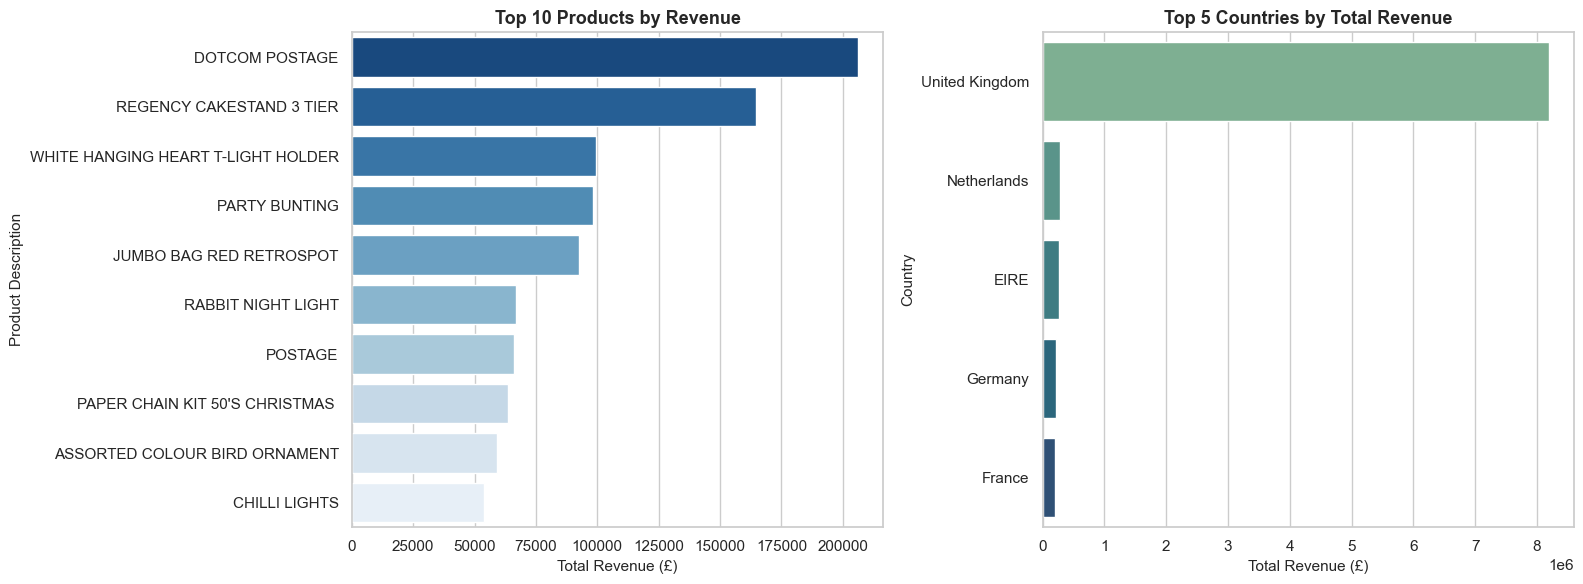

In [10]:
# Guarantee TotalAmount exists
if 'TotalAmount' not in df.columns:
    df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Clean Description: remove null/blank entries
clean_desc_df = df.dropna(subset=['Description'])
clean_desc_df = clean_desc_df[clean_desc_df['Description'].astype(str).str.strip() != '']

# Top 10 products by total revenue
top_products = (
    clean_desc_df.groupby('Description')['TotalAmount']
    .sum()
    .reset_index()
    .sort_values(by='TotalAmount', ascending=False)
    .head(10)
)

# Top 5 countries by total revenue
top_countries = (
    df.groupby('Country')['TotalAmount']
    .sum()
    .reset_index()
    .sort_values(by='TotalAmount', ascending=False)
    .head(5)
)

# Plotting side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Top 10 Products
sns.barplot(
    data=top_products,
    x='TotalAmount',
    y='Description',
    ax=axes[0],
    palette='Blues_r'
)
axes[0].set_title('Top 10 Products by Revenue', fontsize=13, weight='bold')
axes[0].set_xlabel('Total Revenue (£)', fontsize=11)
axes[0].set_ylabel('Product Description', fontsize=11)

# Subplot 2: Top 5 Countries
sns.barplot(
    data=top_countries,
    x='TotalAmount',
    y='Country',
    ax=axes[1],
    palette='crest'
)
axes[1].set_title('Top 5 Countries by Total Revenue', fontsize=13, weight='bold')
axes[1].set_xlabel('Total Revenue (£)', fontsize=11)
axes[1].set_ylabel('Country', fontsize=11)

plt.tight_layout()
plt.show()

### Observations: Product & Geographic Distribution
* **Pareto Distribution**: A small core set of high-demand items generates a disproportionate share of total revenue.
* **Domestic Dominance**: The United Kingdom is by far the largest single contributor to revenue, with international markets like Germany, France, and EIRE representing significant secondary wholesale demand.

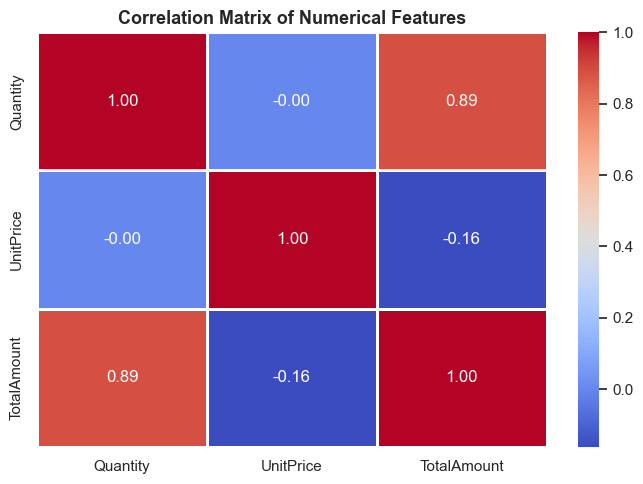

In [11]:
# Ensure TotalAmount exists
if 'TotalAmount' not in df.columns:
    df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

# Select available numerical columns
numerical_cols = ['Quantity', 'UnitPrice', 'TotalAmount']
numerical_df = df[numerical_cols].dropna()

# Compute and plot correlation matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    numerical_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    linewidths=0.8,
    cbar=True
)
plt.title('Correlation Matrix of Numerical Features', fontsize=13, weight='bold')
plt.tight_layout()
plt.show()

### Observations: Correlation Analysis
* **Volume-Driven Revenue**: `TotalAmount` correlates positively with `Quantity`, demonstrating that bulk transaction volume is the primary driver of high invoice values.
* **Pricing Uniformity**: `UnitPrice` exhibits little direct linear correlation with order size, reflecting a stable catalog price structure across wholesale orders.

## Key Findings & Strategic Recommendations

1. **Safety Stock Buffer for Peak Months**:
   * Order volumes rise sharply in Q4 leading into the festive season. Warehouse and logistics planning should expand safety stock by late August to prevent stockouts of top-tier items.

2. **Market Penetration Outside the UK**:
   * While the UK represents the dominant revenue base, sustained purchasing activity in Germany and France indicates established demand. Introducing regional delivery incentives can accelerate European growth.

3. **Product Bundling & Bulk Discounts**:
   * Since the top 10 items account for a major portion of sales volume, bundling slower-moving complementary stock with these core products will improve inventory turnover across all categories.